# SBA 7(a) Small Business Lending Analysis
**Data:** U.S. Small Business Administration, 7(a) FOIA loan data, FY2020 through June 30, 2026 ([data.sba.gov](https://data.sba.gov/dataset/7a-504-foia), public domain).

**Goal:** Understand where SBA-backed small business credit goes, what it costs, and how terms differ by industry, product, business age, lender, and location, with a closer look at Virginia and the Richmond region.

**Workflow:** Python (pandas) for cleaning, SQLite for the analysis queries, matplotlib for charts. Excel and Tableau files are built from the same outputs.

## 1. Load and profile the raw data

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
pd.set_option("display.width", 160)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

raw = pd.read_csv(ROOT / "data/raw/FOIA_7a_FY2020_Present_asof_260630.csv", low_memory=False)
print(f"{len(raw):,} rows x {raw.shape[1]} columns")
raw["LoanStatus"].value_counts()

388,338 rows x 42 columns


LoanStatus
EXEMPT    242061
P I F      68201
CANCLD     50104
COMMIT     21079
CHGOFF      6893
Name: count, dtype: int64

**Data quality notes**
- `CANCLD` loans were approved but never funded, so they are removed to avoid overstating lending.
- `EXEMPT` means the loan is active; SBA withholds its status under FOIA Exemption 4. That means a true default rate **cannot** be calculated from this file (see Section 6).
- FY2026 is a partial year (data runs through June 30, 2026), so it is flagged and not compared directly with full years.

In [2]:
print("Missing values in key fields:")
raw[["GrossApproval", "InitialInterestRate", "TermInMonths", "NaicsCode", "ProjectState", "BusinessAge"]].isna().sum()

Missing values in key fields:


GrossApproval            0
InitialInterestRate      8
TermInMonths             0
NaicsCode                0
ProjectState             0
BusinessAge            186
dtype: int64

## 2. Clean the data
The cleaning logic lives in `src/clean.py` so it can be rerun outside the notebook. It removes cancelled loans, drops borrower names and addresses, maps NAICS codes to industry sectors, and groups processing methods into product families.

In [3]:
import subprocess, sys
print(subprocess.run([sys.executable, str(ROOT / "src/clean.py")], capture_output=True, text=True).stdout)
print(subprocess.run([sys.executable, str(ROOT / "src/build_db.py")], capture_output=True, text=True).stdout)
con = sqlite3.connect(ROOT / "data/processed/sba_7a.db")
q = lambda sql: pd.read_sql_query(sql, con)
q("SELECT COUNT(*) AS funded_loans, ROUND(SUM(GrossApproval)/1e9, 1) AS total_billions FROM loans")

Raw rows: 388,338  |  Cancelled removed: 50,104  |  Clean rows: 338,234
Saved data/processed/loans_clean.parquet



Loaded 338,234 loans into data/processed/sba_7a.db (table: loans)



,funded_loans,total_billions
0,338234,179.1


## 3. Analysis in SQL
Every query is stored in `sql/analysis_queries.sql`. The cells below run each one.

In [4]:
import re
SQL = (ROOT / "sql/analysis_queries.sql").read_text()
parts = re.split(r"^-- name:\s*(\w+)\s*$", SQL, flags=re.M)
Q = {n: re.split(r"^-- Q\d", b, flags=re.M)[0].strip() for n, b in zip(parts[1::2], parts[2::2])}
list(Q)

['yearly_volume',
 'sector_mix',
 'product_comparison',
 'business_age',
 'top_lenders',
 'lender_concentration',
 'state_ranking',
 'virginia_sectors',
 'richmond_region',
 'rate_trend',
 'size_bands',
 'resolved_outcomes']

### Q1. How has lending changed year over year?

In [5]:
q(Q["yearly_volume"])

,fiscal_year,partial_year,loans,total_billions,avg_loan,avg_rate
0,2020,0,36490,19.51,534632.0,6.46
1,2021,0,45360,32.20,709944.0,5.49
2,2022,0,42282,23.27,550336.0,6.42
3,2023,0,51747,24.66,476454.0,10.12
4,2024,0,62618,27.52,439458.0,11.11
5,2025,0,64096,32.07,500280.0,10.24
6,2026,1,35641,19.89,557930.0,9.50


### Q2. Which industries receive the most dollars?

In [6]:
q(Q["sector_mix"]).head(10)

,Sector,loans,total_billions,pct_of_dollars,avg_loan
0,Accommodation & Food Services,42538,31.45,17.6,739360.0
1,Retail Trade,41250,24.80,13.8,601233.0
2,Health Care & Social Assistance,32313,19.69,11.0,609395.0
3,Construction,43592,16.22,9.1,372087.0
4,Other Services,32351,15.00,8.4,463630.0
5,Manufacturing,20997,14.23,7.9,677576.0
6,Professional & Technical Services,31918,13.64,7.6,427208.0
7,Wholesale Trade,14394,9.57,5.3,664851.0
8,"Admin, Support & Waste Services",19634,7.00,3.9,356345.0
9,"Arts, Entertainment & Recreation",12060,6.13,3.4,508550.0


### Q3. How do the loan products compare?

In [7]:
q(Q["product_comparison"])

,product,loans,pct_of_loans,pct_of_dollars,avg_loan,avg_rate,avg_term_months,avg_guarantee_pct
0,Preferred Lender (PLP),182849,54.1,80.1,784474.0,8.60,161.0,78.9
1,SBA Express,130232,38.5,7.6,104770.0,9.22,106.0,52.1
2,Standard 7(a),20530,6.1,10.1,883010.0,7.73,158.0,78.4
3,Other,4623,1.4,2.2,841939.0,8.27,112.0,82.1


### Q4. Do startups and newer businesses get different terms?

In [8]:
q(Q["business_age"])

,BusinessAge,loans,pct_of_loans,avg_loan,avg_rate,pct_collateralized,pct_franchise
0,Existing (2+ years),184576,54.6,436853.0,9.00,78.6,3.8
1,New (2 years or less),56540,16.7,453159.0,9.03,71.4,9.7
2,Startup,56152,16.6,530192.0,8.45,94.0,40.4
3,Change of Ownership,37097,11.0,1129553.0,7.88,97.7,17.3
4,Unanswered,3869,1.1,304120.0,8.23,56.9,8.6


### Q5. How concentrated is the lender market?

In [9]:
q(Q["lender_concentration"])

,lenders,top10_pct_of_dollars,top50_pct_of_dollars
0,2150,27.0,56.3


In [10]:
q(Q["top_lenders"])

,lender,loans,total_billions,pct_of_dollars,avg_loan
0,Live Oak Banking Company,9660,13.10,7.3,1355849.0
1,The Huntington National Bank,38974,10.07,5.6,258429.0
2,"Readycap Lending, LLC",9054,3.91,2.2,431978.0
3,"U.S. Bank, National Association",15246,3.82,2.1,250747.0
4,Celtic Bank Corporation,5338,3.62,2.0,678326.0
5,"Newtek Bank, National Association",8564,3.20,1.8,373656.0
6,Wells Fargo Bank National Association,11230,3.13,1.7,278742.0
7,Byline Bank,2583,3.08,1.7,1191556.0
8,"TD Bank, National Association",15124,2.27,1.3,150221.0
9,First Internet Bank of Indiana,1723,2.23,1.2,1295759.0


### Q6 to Q8. Where does the money go geographically? Virginia and Greater Richmond

In [11]:
st = q(Q["state_ranking"]); st[st.state.isin(["CA","TX","FL","VA"])]

,rank_by_dollars,state,loans,total_billions,avg_loan
0,1,CA,38878,24.83,638717.0
1,2,TX,25765,19.18,744372.0
2,3,FL,24651,14.15,573851.0
17,18,VA,5686,3.14,551791.0


In [12]:
q(Q["virginia_sectors"])

,Sector,loans,total_millions,pct_of_va_dollars
0,Accommodation & Food Services,789,694.9,22.1
1,Professional & Technical Services,818,396.3,12.6
2,Health Care & Social Assistance,629,386.0,12.3
3,Other Services,565,266.1,8.5
4,Construction,602,264.9,8.4
5,Retail Trade,543,256.9,8.2
6,Manufacturing,283,178.6,5.7
7,"Arts, Entertainment & Recreation",273,169.0,5.4


In [13]:
q(Q["richmond_region"])

,locality,loans,total_millions,avg_loan
0,HENRICO,258,151.0,585366.0
1,CHESTERFIELD,237,140.2,591726.0
2,HANOVER,105,67.0,637804.0
3,RICHMOND CITY,170,64.0,376288.0


### Q9. How did borrowing costs change?

In [14]:
q(Q["rate_trend"])

,quarter,loans,avg_rate,avg_variable_rate
0,2019-Q4,10394,7.35,7.54
1,2020-Q1,8771,7.19,7.43
2,2020-Q2,6942,5.70,5.85
3,2020-Q3,10383,5.46,5.56
4,2020-Q4,7618,5.66,5.76
5,2021-Q1,8561,5.53,5.64
6,2021-Q2,12142,5.45,5.56
7,2021-Q3,17039,5.42,5.52
8,2021-Q4,7858,5.73,5.82
9,2022-Q1,10158,5.74,5.81


### Q10. Loan size distribution

In [15]:
q(Q["size_bands"])

,SizeBand,loans,pct_of_loans,pct_of_dollars
0,Under $50K,60549,17.9,0.8
1,$50K-$150K,75966,22.5,3.5
2,$150K-$350K,77585,22.9,9.5
3,$350K-$1M,73851,21.8,23.4
4,$1M-$5M,50283,14.9,62.9


## 4. Outcomes among resolved loans (with a major caveat)
Most funded loans are still active, and SBA does not disclose their status. This query only compares loans that have already ended (paid in full or charged off). Because loans that end early are not a random sample, these percentages are **directional only** and are not default rates.

In [16]:
q(Q["resolved_outcomes"])

,BusinessAge,resolved_loans,charged_off,chargeoff_pct_of_resolved
0,New (2 years or less),12725,1750,13.8
1,Startup,11456,1087,9.5
2,Existing (2+ years),40845,3487,8.5
3,Change of Ownership,7483,338,4.5


## 5. Charts

0


Charts saved to images/: ['01_yearly_volume.png', '02_sector_mix.png', '03_rate_trend.png', '04_size_bands.png', '05_resolved_outcomes.png']



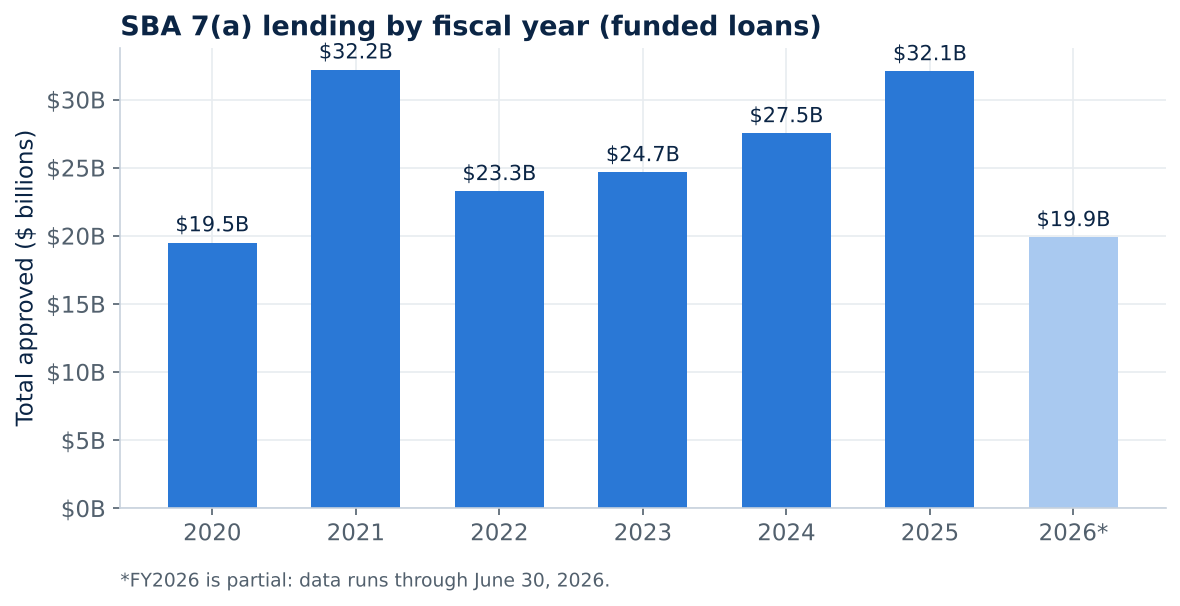

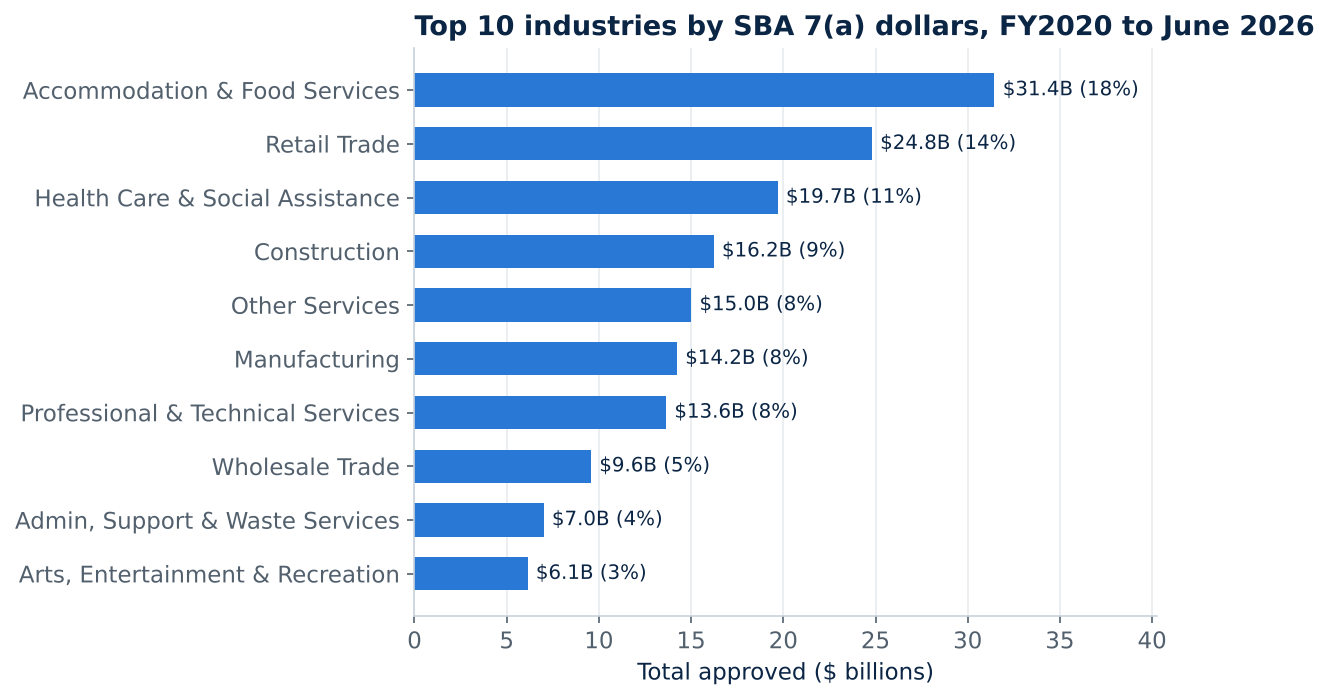

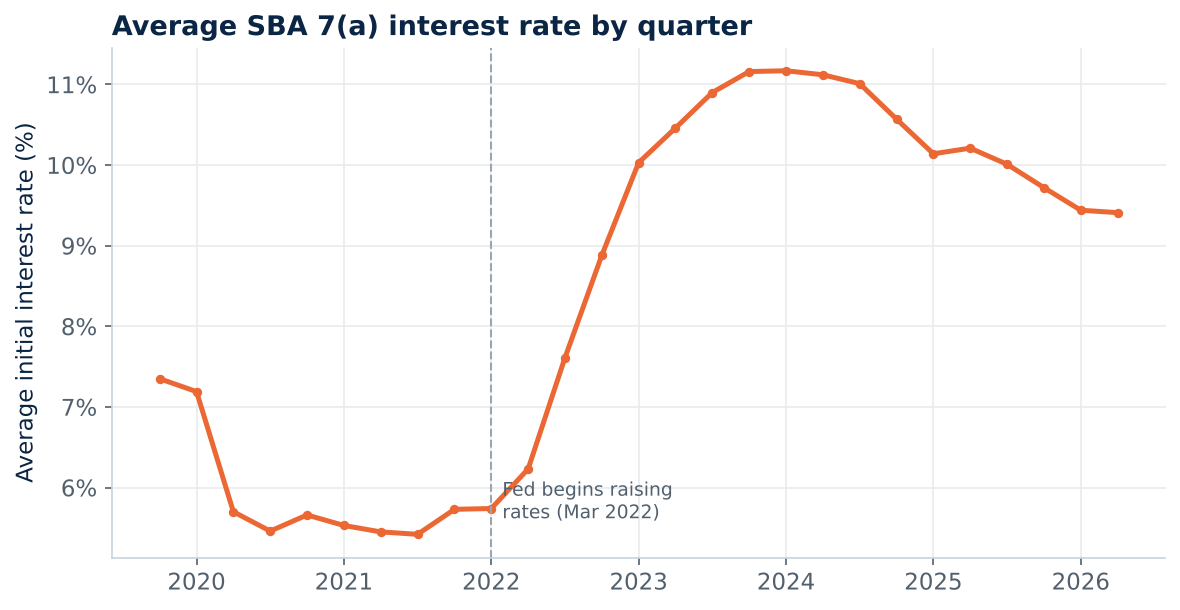

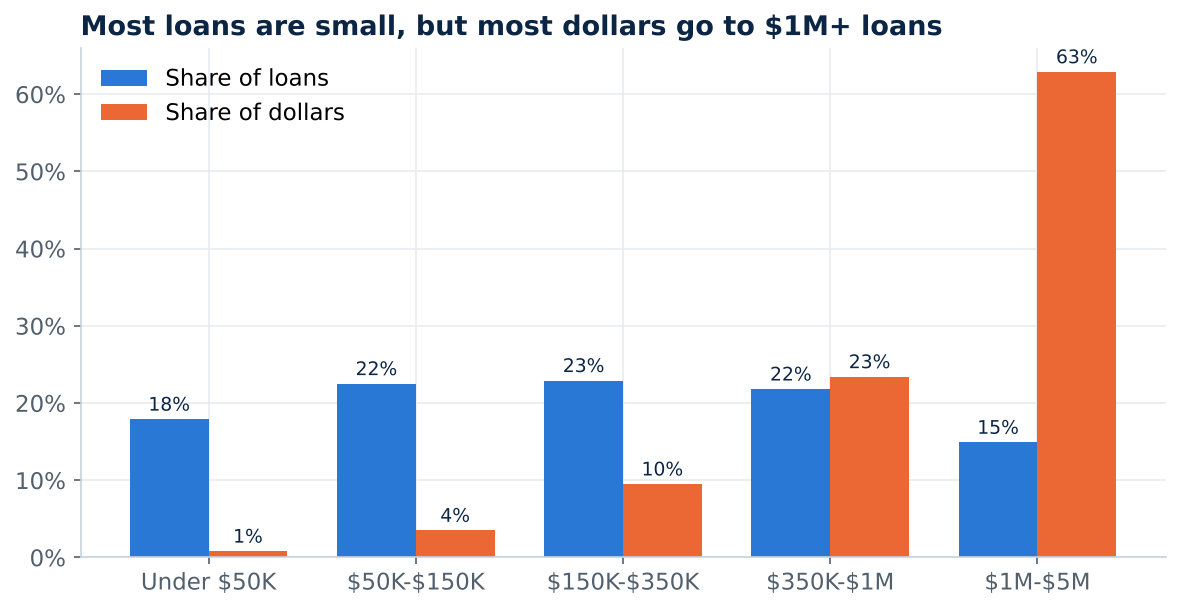

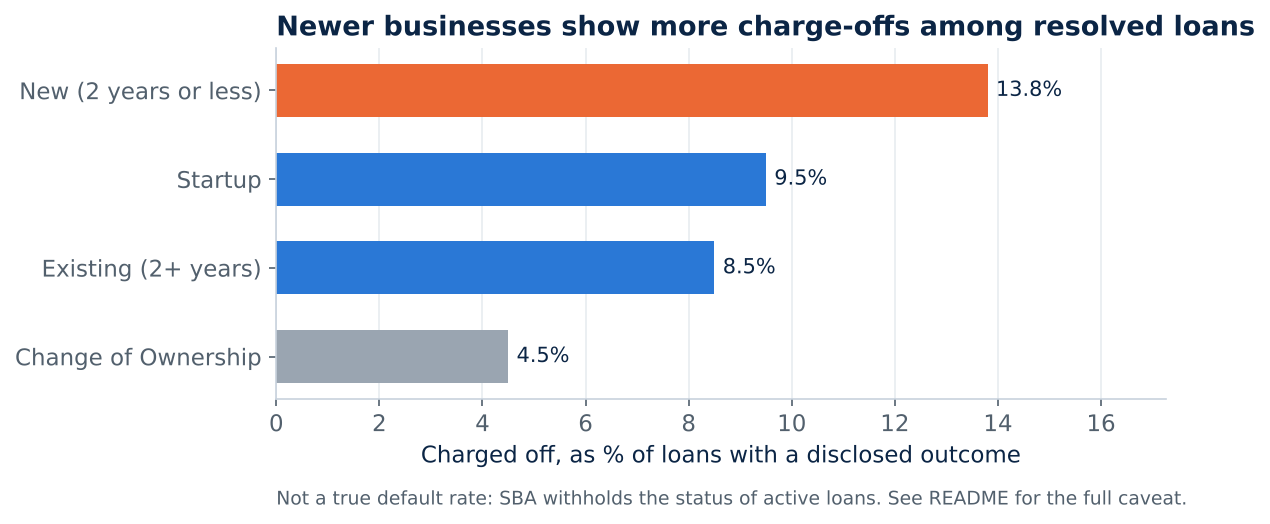

In [17]:
print(subprocess.run([sys.executable, str(ROOT / "src/run_queries.py")], capture_output=True, text=True).returncode)
print(subprocess.run([sys.executable, str(ROOT / "src/make_charts.py")], capture_output=True, text=True).stdout)
from IPython.display import Image, display
for name in sorted((ROOT / "images").glob("*.png")):
    display(Image(filename=str(name), width=720))

## 6. Key findings
See the README for the full write-up. In short:
1. **Lending recovered and grew** to about $32.1B in FY2025 even as the average rate roughly doubled from 2021 lows.
2. **Restaurants and hotels lead** (Accommodation & Food Services, about 18% of dollars).
3. **Size is lopsided:** loans of $1M+ are about 15% of loans but about 63% of dollars.
4. **Products split the market:** SBA Express is about 39% of loans but under 8% of dollars.
5. **Lending is moderately concentrated:** the top 10 of about 2,150 lenders hold 27% of dollars.
6. **Newer businesses show more charge-offs among resolved loans**, with the caveat above.